# Seminar 1 · Part 4: The handwritten digits (MNIST)

**The story of today** (from the book *Probability and Statistics for Data Science*, section 4.8):

1. **Goal.** Estimate the conditional pmf of the class $\tilde{y}$ given the features $\tilde{x}$: $\;p_{\tilde{y}\mid\tilde{x}}(y \mid x)$. Then predict the most likely class, $\mathrm{MAP}(x) = \arg\max_y p_{\tilde{y}\mid\tilde{x}}(y \mid x)$.
2. **Attempt 1: just count.** $p_{\tilde{y}\mid\tilde{x}}(y \mid x) = p_{\tilde{x},\tilde{y}}(x, y) \,/\, p_{\tilde{x}}(x)$, and count the training examples equal to $x$. It fails: almost every new $x$ was never seen (the **curse of dimensionality**).
3. **Attempt 2: build the joint pmf from small pieces.** With the naive Bayes assumption (the features are conditionally independent given the class):
$$p_{\tilde{y}\mid\tilde{x}}(y \mid x) = \frac{p_{\tilde{y}}(y)\prod_{j=1}^{d} p_{\tilde{x}[j]\mid\tilde{y}}(x[j] \mid y)}{\sum_{k} p_{\tilde{y}}(k)\prod_{j=1}^{d} p_{\tilde{x}[j]\mid\tilde{y}}(x[j] \mid k)}$$
We only need to estimate the prior $p_{\tilde{y}}$ and one small pmf (or pdf) per feature and class.

**scikit-learn** does all the counting and the computing for us. We read what it learned and check it against the slides.

Here: $x$ is an image of $d = 784$ black-or-white pixels, $x[j] = 1$ if pixel $j$ has ink, and the class is the digit $0, 1, \dots, 9$.

**How to use this notebook:** run the cells one by one from the top, with **Shift + Enter**. Read the text cells: they explain what each code cell does.

In [1]:
import gzip
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import BernoulliNB             # naive Bayes with one Bernoulli per pixel and digit
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score

SEED = 0                                                # fixed random seed: everyone gets the same "dreams"

## 1. Load the data

The first time, this cell downloads the 4 MNIST files (about 11 MB) into `data/mnist/`. You do not need to read this cell.

In [2]:
DATA = Path("..") / "data" / "mnist"
URL = "https://raw.githubusercontent.com/fgnt/mnist/master/"


def load_mnist(part):
    '''part = "train" (60,000 images) or "t10k" (10,000 test images).
    Returns the gray levels (one row of 784 numbers per image, pixels row by row) and the digits.'''
    arrays = []
    for name, header in [(f"{part}-images-idx3-ubyte.gz", 16), (f"{part}-labels-idx1-ubyte.gz", 8)]:
        path = DATA / name
        if not path.exists():
            DATA.mkdir(parents=True, exist_ok=True)
            print("Downloading", name, "...")
            urllib.request.urlretrieve(URL + name, path)
        arrays.append(np.frombuffer(gzip.open(path).read(), np.uint8, offset=header))
    images, digits = arrays
    return images.reshape(-1, 784), digits


X_train, y_train = load_mnist("train")
X_test, y_test = load_mnist("t10k")
print("Training set:", X_train.shape, "  (images, pixels)")
print("Test set:    ", X_test.shape)

Training set: (60000, 784)   (images, pixels)
Test set:     (10000, 784)


## 2. Look at the data

### How many images of each digit?

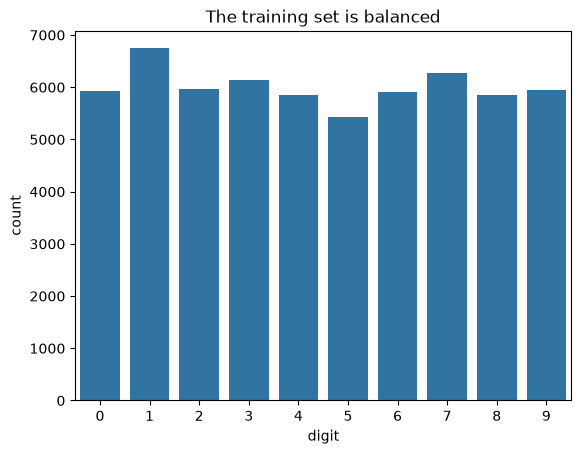

In [3]:
sns.countplot(x=y_train)
plt.xlabel("digit")
plt.title("The training set is balanced")
plt.show()

### One image = 784 gray levels, from 0 (white) to 255 (black ink)

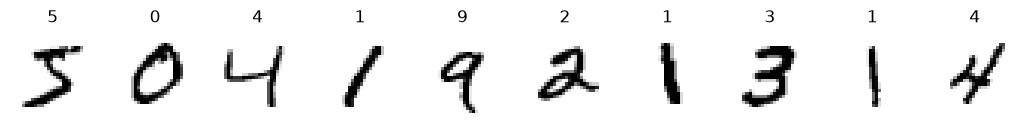

In [4]:
fig, axes = plt.subplots(1, 10, figsize=(13, 1.6))
for i, ax in enumerate(axes):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray_r")
    ax.set_title(str(y_train[i]))
    ax.axis("off")
plt.show()

### Which gray levels? Almost black or white

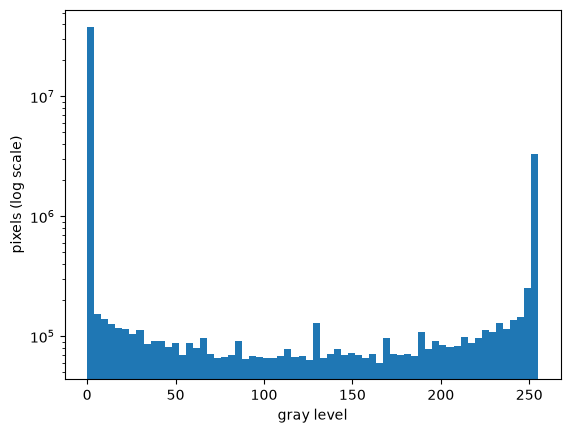

pixels that are exactly 0: 80.9%


In [5]:
plt.hist(X_train.ravel(), bins=64, log=True)
plt.xlabel("gray level")
plt.ylabel("pixels (log scale)")
plt.show()
print(f"pixels that are exactly 0: {(X_train == 0).mean():.1%}")

### Binarization: ink = gray level above 127

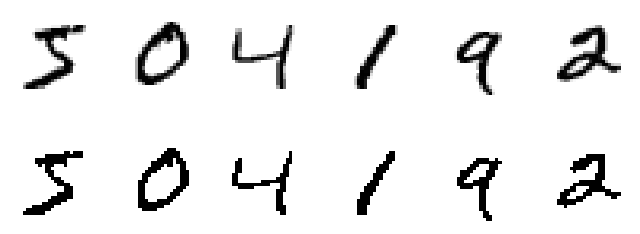

In [6]:
fig, axes = plt.subplots(2, 6, figsize=(8, 3))
for i in range(6):
    axes[0, i].imshow(X_train[i].reshape(28, 28), cmap="gray_r")
    axes[1, i].imshow((X_train[i] > 127).reshape(28, 28), cmap="gray_r")
    axes[0, i].axis("off"); axes[1, i].axis("off")
plt.show()

## 3. Attempt 1: just count

There are $2^{784} \approx 10^{236}$ possible black-and-white images. How many test images are **exactly** equal to a training image?

In [7]:
train_images = {bytes(row) for row in (X_train > 127).astype(np.uint8)}     # every training image, as a key
seen = sum(bytes(row) in train_images for row in (X_test > 127).astype(np.uint8))
print("Different training images:", len(train_images), "of", len(X_train))
print("Test images seen in the training set:", seen, "of", len(X_test))

Different training images: 59984 of 60000
Test images seen in the training set: 9 of 10000


For almost every test image, counting gives $0/0$: the curse of dimensionality.

## 4. Attempt 2: Bernoulli naive Bayes

Given the digit $y$, each pixel is Bernoulli with $\theta_{y,j}$ = the probability of ink at pixel $j$, and the pixels are conditionally independent:
$$p_{\tilde{x}\mid\tilde{y}}(x \mid y) = \prod_{j=1}^{784} \theta_{y,j}^{\,x[j]} (1 - \theta_{y,j})^{1 - x[j]}$$

`BernoulliNB(binarize=127)` binarizes the images (ink = above 127), counts, and uses Laplace smoothing (`alpha=1`): $\theta_{y,j} = \dfrac{n_{y,j} + 1}{n_y + 2}$.

In [8]:
model = BernoulliNB(binarize=127, alpha=1)
model.fit(X_train, y_train)

prior = np.exp(model.class_log_prior_)                  # p(y) = n_y / n
theta = np.exp(model.feature_log_prob_)                 # theta[y, j - 1] = probability of ink at pixel j for digit y
print("Prior:", prior.round(3))
print("Numbers in the model:", theta.size + prior.size)

Prior: [0.099 0.112 0.099 0.102 0.097 0.09  0.099 0.104 0.098 0.099]
Numbers in the model: 7850


### What is inside the trained model?

`fit` only counts. The model keeps the counts, and the estimates made from them, as **attributes**: names that end with `_`.

Here $n = 60{,}000$ is the number of training images. Pixel $j$ is in column $j - 1$ of the arrays (Python counts from 0).

| Attribute | Shape | What it is |
|---|---|---|
| `classes_` | 10 | The digits $y = 0, 1, \dots, 9$. Row $y$ of the arrays below belongs to the digit $y$. |
| `class_count_` | 10 | $n_y$: the number of training images of the digit $y$. |
| `class_log_prior_` | 10 | $\log p_{\tilde{y}}(y)$, where $p_{\tilde{y}}(y) = n_y / n$. |
| `feature_count_` | 10 × 784 | $n_{y,j}$: the number of training images of the digit $y$ with ink at pixel $j$. |
| `feature_log_prob_` | 10 × 784 | $\log \theta_{y,j}$, with Laplace smoothing (`alpha=1`): $\;\theta_{y,j} = \dfrac{n_{y,j} + 1}{n_y + 2}$ |
| `n_features_in_` | number | $d = 784$, the number of pixels. |

- The probabilities are stored as **logs**. `np.exp` gives them back: that is `prior` and `theta` in the cell above.
- **Careful:** the scikit-learn documentation writes `feature_log_prob_` as $P(x_i \mid y)$. It is only the **ink** side, $\log \theta_{y,j} = \log p_{\tilde{x}[j]\mid\tilde{y}}(1 \mid y)$. The probability of no ink, $1 - \theta_{y,j}$, is not stored.
- `binarize=127` means: ink if the gray level is **strictly** above 127 (127 is white, 128 is ink).
- The attribute `feature_names_in_` is **not set here**, because `X_train` is a plain array with no column names.

In [9]:
print("classes_:      ", model.classes_)
print("class_count_:  ", model.class_count_.astype(int), "  (n_y)")
print("n_features_in_:", model.n_features_in_, "  (d)")
print("feature_count_ shape:   ", model.feature_count_.shape)       # (10 digits, 784 pixels)
print("feature_log_prob_ shape:", model.feature_log_prob_.shape)

classes_:       [0 1 2 3 4 5 6 7 8 9]
class_count_:   [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]   (n_y)
n_features_in_: 784   (d)
feature_count_ shape:    (10, 784)
feature_log_prob_ shape: (10, 784)


The two big arrays, at two pixels: pixel 1 (the top-left corner) and pixel 378 (in the middle, used again in section 8).

In [10]:
pixels = [1, 378]
table = {}
for j in pixels:
    table[f"n_y,{j}"] = model.feature_count_[:, j - 1].astype(int)       # column j - 1 = pixel j
    table[f"theta_y,{j}"] = theta[:, j - 1].round(4)
pd.DataFrame(table, index=pd.Index(model.classes_, name="digit y"))

,"n_y,1","theta_y,1","n_y,378","theta_y,378"
digit y,,,,
0,0,0.0002,423,0.0716
1,0,0.0001,4441,0.6587
2,0,0.0002,1349,0.2265
3,0,0.0002,4825,0.7869
4,0,0.0002,1113,0.1906
5,0,0.0002,3049,0.5624
6,0,0.0002,1813,0.3064
7,0,0.0002,185,0.0297
8,0,0.0002,4167,0.7121


No training image has ink in the corner: $n_{y,1} = 0$ for every digit, but $\theta_{y,1} > 0$. That is Laplace smoothing at work.

### Check: training = counting

We count by ourselves, from `X_train`, and compare with what the model stored.

In [11]:
X_bin = X_train > 127                                                     # binarization: True = ink
n_y = np.array([(y_train == y).sum() for y in range(10)])                 # n_y, for y = 0, ..., 9
n_yj = np.array([X_bin[y_train == y].sum(axis=0) for y in range(10)])     # n_{y,j}: one row per digit, one column per pixel
theta_ours = (n_yj + 1) / (n_y[:, None] + 2)                              # Laplace smoothing

print("n_y            :", np.array_equal(n_y, model.class_count_))
print("n_{y,j}        :", np.array_equal(n_yj, model.feature_count_))
print("prior  n_y / n :", np.allclose(n_y / len(y_train), prior))
print("theta_{y,j}    :", np.allclose(theta_ours, theta))

n_y            : True
n_{y,j}        : True
prior  n_y / n : True
theta_{y,j}    : True


### Why smoothing? The zero-count problem

`feature_count_[y, j - 1]` = $n_{y,j}$, the number of training images of $y$ with ink at pixel $j$.

In [12]:
never = (model.feature_count_[1] == 0).sum()
print(f"Pixels with no ink in any of the {int(model.class_count_[1])} training 1s:", never)

Pixels with no ink in any of the 6742 training 1s: 309


### Trap question: a blank page

No ink at all. What does the classifier say?

In [13]:
blank = np.zeros((1, 784))
posterior = model.predict_proba(blank)[0]
print("MAP(x) =", model.predict(blank)[0])
print("posterior of the other 9 digits, together:", posterior[np.arange(10) != 1].sum())

MAP(x) = 1
posterior of the other 9 digits, together: 5.379608479077712e-14


## 5. Evaluate it

scikit-learn puts the **true** digit in the rows and the **predicted** digit in the columns.

accuracy = 0.8427


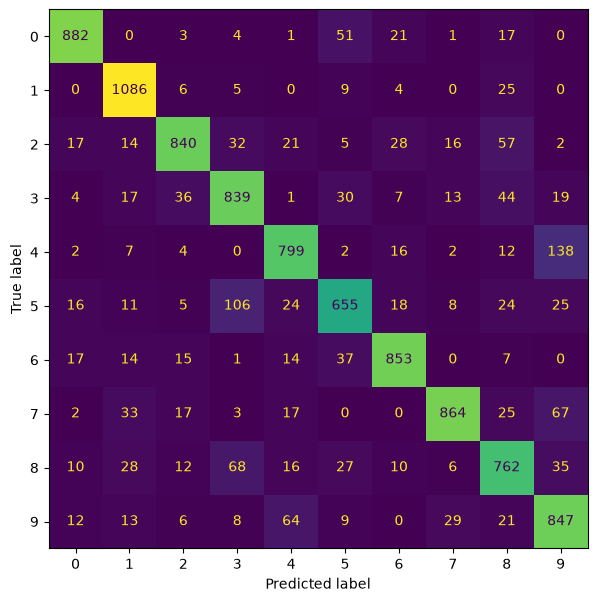

In [14]:
predicted = model.predict(X_test)
print(f"accuracy = {accuracy_score(y_test, predicted):.4f}")

fig, ax = plt.subplots(figsize=(7, 7))
ConfusionMatrixDisplay.from_predictions(y_test, predicted, ax=ax, colorbar=False)
plt.show()

### How sure is it, when it is wrong?

wrong answers with a posterior above 0.99: 67.0%


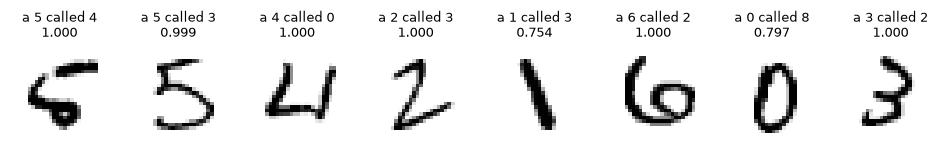

In [15]:
sure = model.predict_proba(X_test).max(axis=1)           # the posterior of the predicted digit
wrong = predicted != y_test
print(f"wrong answers with a posterior above 0.99: {(sure[wrong] > 0.99).mean():.1%}")

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, i in zip(axes, np.flatnonzero(wrong)[:8]):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray_r")
    ax.set_title(f"a {y_test[i]} called {predicted[i]}\n{sure[i]:.3f}", fontsize=9)
    ax.axis("off")
plt.show()

## 6. What the machine thinks each digit looks like

The 784 numbers $\theta_{y,1}, \dots, \theta_{y,784}$ of each digit, as a $28 \times 28$ picture.

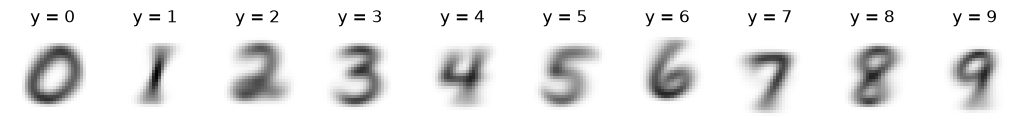

In [16]:
fig, axes = plt.subplots(1, 10, figsize=(13, 1.6))
for y, ax in enumerate(axes):
    ax.imshow(theta[y].reshape(28, 28), cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"y = {y}")
    ax.axis("off")
plt.show()

## 7. Let the machine dream

The model is the joint pmf, so it can **generate** images: choose a digit $y$, then give each pixel ink with probability $\theta_{y,j}$, independently.

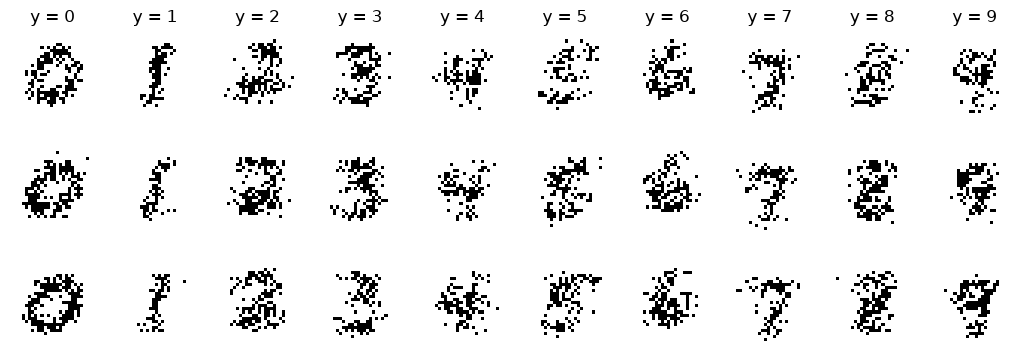

In [17]:
rng = np.random.default_rng(SEED)


def dream(y):
    '''One random image of the digit y: pixel j has ink with probability theta[y, j - 1], independently.'''
    return (rng.random(784) < theta[y]).astype(float)


fig, axes = plt.subplots(3, 10, figsize=(13, 4.2))
for y in range(10):
    for row in range(3):
        axes[row, y].imshow(dream(y).reshape(28, 28), cmap="gray_r")
        axes[row, y].axis("off")
    axes[0, y].set_title(f"y = {y}")
plt.show()

### Can the machine read its own dreams?

In [18]:
dreams = np.array([dream(y) for y in range(10) for _ in range(100)])     # 100 dreams of each digit
dream_digits = np.repeat(np.arange(10), 100)
print("accuracy on 1,000 dreams:", accuracy_score(dream_digits, model.predict(dreams * 255)))   # * 255: ink = black

accuracy on 1,000 dreams: 1.0


## 8. How the independence assumption fails us

Two neighbouring pixels in the middle: $j = 378$ and $j' = 379$ (Python counts from 0: columns 377 and 378), inside the training 5s.

In [19]:
ink = (X_train[y_train == 5] > 127).astype(float)
a, b = ink[:, 377], ink[:, 378]
print("training 5s:", len(ink))
print(f"ink at j: {a.mean():.3f}   ink at j': {b.mean():.3f}   ink at both: {(a * b).mean():.3f}   product: {a.mean() * b.mean():.3f}")
print(f"correlation: {np.corrcoef(a, b)[0, 1]:.2f}")

training 5s: 5421
ink at j: 0.562   ink at j': 0.494   ink at both: 0.463   product: 0.278
correlation: 0.75


Conditionally independent would mean: both = product, and correlation 0. False: ink comes in strokes.

## Summary

- $2^{784}$ possible images: counting fails. Naive Bayes needs only $10 \times 784 + 10 = 7{,}850$ numbers.
- `BernoulliNB`: training = counting ink, with Laplace smoothing.
- The model is generative (it can dream), and overconfident (its wrong answers are often very sure).

**Read more:** Fernandez-Granda, *Probability and Statistics for Data Science*, section 4.8. Murphy, *Probabilistic Machine Learning: An Introduction*, section 9.3.